# Turbofan Engine Remaining Useful Life (RUL) — FD001

This notebook loads NASA C-MAPSS FD001 data, creates per-engine rolling sensor features, compares baseline models with engine-level cross-validation, evaluates an RUL-cap candidate on training engines only, then reports an uncapped baseline and the final capped model on the official test set, followed by error analysis and SHAP feature attributions.

**Validation and disclosure note**
- Official test labels are used only for final reporting (sections 9–10). No code in the cap-selection experiment (section 8) reads them, and `RUL_CAP` is a fixed constant.
- The idea of capping the training target was a response to over-prediction observed in the uncapped baseline's official test results, and the random-cut validation range (7–145 cycles) mirrors the official test label range. The cap is therefore a *candidate informed by test diagnostics*, validated on training data, and the final test score should not be read as a fully untouched hold-out result.
- Cross-validation metrics (all cycles of held-out training engines) and official test metrics (one last observed cycle per test engine) describe different row populations and must not be compared directly.


## 1. Imports and paths

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost
import shap

from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

print("Python:", sys.version.split()[0])
for lib in (np, pd, matplotlib, sklearn, xgboost, shap):
    print(f"{lib.__name__}: {lib.__version__}")

# Run this notebook from the notebooks/ folder so that ../data resolves correctly.
DATA_DIR = "../data"
assert os.path.isdir(DATA_DIR), f"Data folder not found: {DATA_DIR}"
print("Data files:", sorted(f for f in os.listdir(DATA_DIR) if not f.startswith(".")))

Python: 3.13.9
numpy: 2.3.5
pandas: 2.3.3
matplotlib: 3.10.6
sklearn: 1.7.2
xgboost: 3.4.1
shap: 0.52.0
Data files: ['RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']


C:\Users\HP\anaconda3\envs\rul-fd001-test\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the FD001 data

In [2]:
columns = ["unit", "cycle", "setting_1", "setting_2", "setting_3"]
columns += [f"s_{i}" for i in range(1, 22)]

train_raw = pd.read_csv(
    os.path.join(DATA_DIR, "train_FD001.txt"),
    sep=r"\s+", header=None, names=columns
)
test_raw = pd.read_csv(
    os.path.join(DATA_DIR, "test_FD001.txt"),
    sep=r"\s+", header=None, names=columns
)
rul_df = pd.read_csv(
    os.path.join(DATA_DIR, "RUL_FD001.txt"), header=None, names=["RUL"]
)

print("Train shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
print("Official RUL shape:", rul_df.shape)

# Basic dataset consistency checks.
assert train_raw.shape[1] == 26, "Unexpected number of training columns"
assert test_raw.shape[1] == 26, "Unexpected number of test columns"
assert len(rul_df) == test_raw["unit"].nunique(), (
    "Official RUL rows must match the number of test engines"
)
display(train_raw.head())
display(test_raw.head())
display(rul_df.head())

Train shape: (20631, 26)
Test shape: (13096, 26)
Official RUL shape: (100, 1)


,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


,RUL
0,112
1,98
2,69
3,82
4,91


## 3. Data quality and training target

In [3]:
print("Missing values — train:", int(train_raw.isna().sum().sum()))
print("Missing values — test:", int(test_raw.isna().sum().sum()))
print("Training engines:", train_raw["unit"].nunique())
print("Test engines:", test_raw["unit"].nunique())

max_cycle = train_raw.groupby("unit")["cycle"].max()
train_raw["RUL"] = train_raw["unit"].map(max_cycle) - train_raw["cycle"]

display(train_raw[["unit", "cycle", "RUL"]].head())
display(train_raw["RUL"].describe())

Missing values — train: 0
Missing values — test: 0
Training engines: 100
Test engines: 100


,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

In [4]:
constant_columns = [
    col for col in train_raw.columns
    if col not in {"unit", "cycle", "RUL"}
    and train_raw[col].nunique(dropna=False) <= 1
]
print("Constant columns:", constant_columns)

Constant columns: ['setting_3', 's_1', 's_5', 's_10', 's_16', 's_18', 's_19']


## 4. Quick exploratory analysis

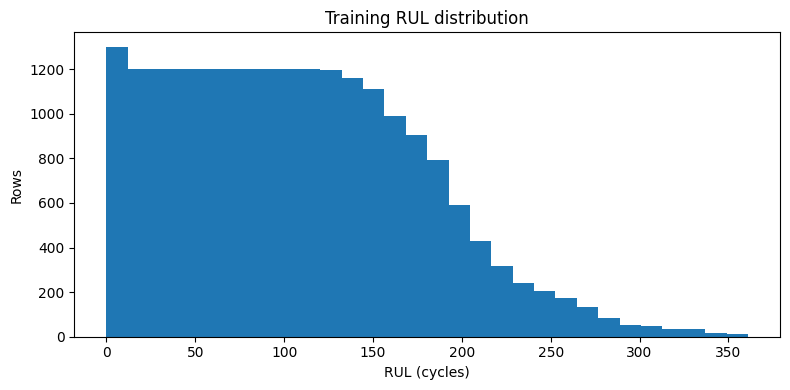

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(train_raw["RUL"], bins=30)
plt.xlabel("RUL (cycles)")
plt.ylabel("Rows")
plt.title("Training RUL distribution")
plt.tight_layout()
plt.show()

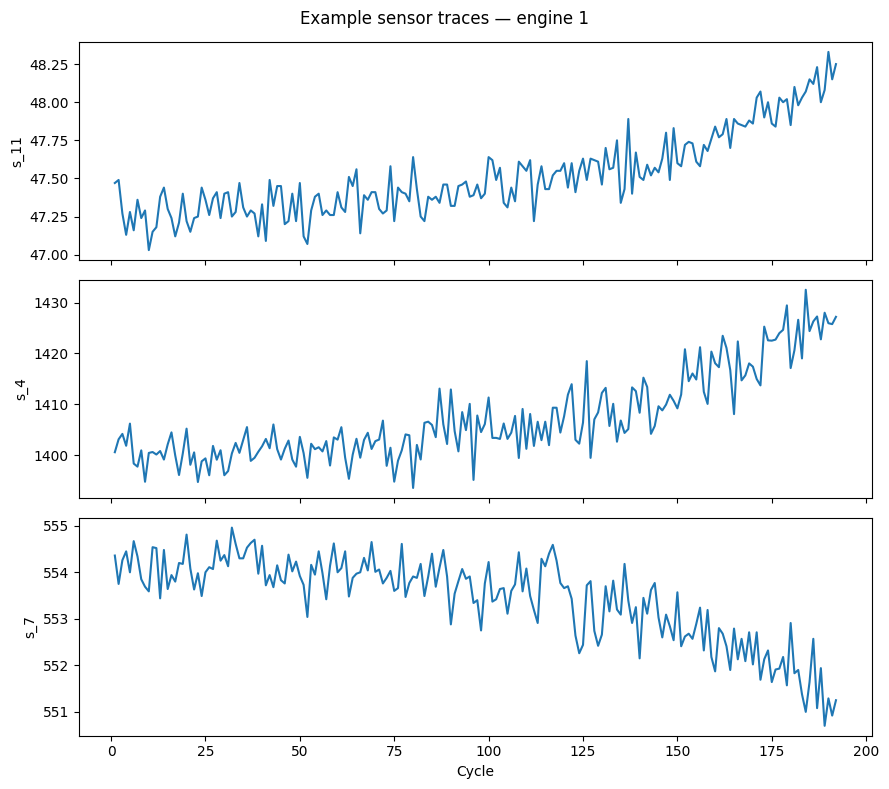

In [6]:
engine_1 = train_raw.loc[train_raw["unit"] == 1]
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, sensor in zip(axes, ["s_11", "s_4", "s_7"]):
    ax.plot(engine_1["cycle"], engine_1[sensor])
    ax.set_ylabel(sensor)
axes[-1].set_xlabel("Cycle")
fig.suptitle("Example sensor traces — engine 1")
fig.tight_layout()
plt.show()

## 5. Feature engineering

In [7]:
ROLLING_FEATURES = {
    "s_4": ["mean", "std"],
    "s_11": ["mean", "std"],
}

def add_rolling_features(frame, window=5):
    """Add per-engine rolling sensor statistics and remove incomplete windows."""
    result = frame.copy()
    for sensor, statistics in ROLLING_FEATURES.items():
        grouped = result.groupby("unit")[sensor]
        for statistic in statistics:
            name = f"{sensor}_roll_{statistic}_{window}"
            result[name] = (
                grouped.rolling(window)
                .agg(statistic)
                .reset_index(level=0, drop=True)
            )
    return result.dropna().copy()

train_fe = add_rolling_features(train_raw)
test_fe = add_rolling_features(test_raw)

y = train_fe["RUL"].copy()
X = train_fe.drop(columns=["RUL", "unit", *constant_columns])
test_last = test_fe.groupby("unit", sort=True).tail(1).sort_values("unit").copy()
test_X_final = test_last.drop(columns=["unit", *constant_columns])

# Training and test features must have identical names and order (fail loudly otherwise).
assert list(test_X_final.columns) == list(X.columns), "Train/test feature mismatch"
assert len(X) == len(y), "Training features and target length mismatch"
assert test_last["unit"].nunique() == len(rul_df), (
    "One final feature row is required for each official test RUL label"
)

print("Train features:", X.shape)
print("Target:", y.shape)
print("Official test features:", test_X_final.shape)
print("Feature columns match:", X.columns.equals(test_X_final.columns))
print("Missing train feature values:", int(X.isna().sum().sum()))
print("Missing test feature values:", int(test_X_final.isna().sum().sum()))

Train features: (20231, 22)
Target: (20231,)
Official test features: (100, 22)
Feature columns match: True
Missing train feature values: 0
Missing test feature values: 0


## 6. Validation setup and metric

In [8]:
xgb_params = {
    "n_estimators": 100,
    "max_depth": 4,
    "learning_rate": 0.1,
    "random_state": 42,
    "n_jobs": -1,
}

N_SPLITS = 5
group_kfold = GroupKFold(n_splits=N_SPLITS)
groups = train_fe["unit"].to_numpy()

def phm08_score(y_true, y_pred):
    """Asymmetric PHM08 score; lower is better."""
    errors = np.asarray(y_pred) - np.asarray(y_true)
    penalties = np.where(
        errors < 0,
        np.exp(-errors / 13) - 1,
        np.exp(errors / 10) - 1,
    )
    return float(np.sum(penalties))

def regression_metrics(y_true, y_pred):
    errors = np.asarray(y_pred) - np.asarray(y_true)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "PHM08": phm08_score(y_true, y_pred),
        "Mean Error": float(np.mean(errors)),
    }

print("GroupKFold splits:", group_kfold.get_n_splits())
print("Unique engines represented:", len(np.unique(groups)))

GroupKFold splits: 5
Unique engines represented: 100


## 7. Baseline model comparison

In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(**xgb_params),
}

cv_rows = []
for model_name, estimator in models.items():
    fold_rmse = -cross_val_score(
        estimator, X, y, cv=group_kfold, groups=groups,
        scoring="neg_root_mean_squared_error", n_jobs=1
    )
    cv_rows.append({
        "Model": model_name,
        "Mean CV RMSE": fold_rmse.mean(),
        "Fold RMSE": np.round(fold_rmse, 3).tolist(),
    })

cv_comparison = pd.DataFrame(cv_rows)
display(cv_comparison)

,Model,Mean CV RMSE,Fold RMSE
0,Linear Regression,40.046185,"[45.417, 42.415, 37.947, 39.899, 34.553]"
1,Random Forest,37.540545,"[40.472, 38.257, 35.489, 39.122, 34.363]"
2,XGBoost,37.240710,"[40.567, 37.798, 35.652, 38.558, 33.629]"


## 8. Capped-target experiment (training data only)

In [10]:
# Random-cut validation using training engines only.
# For each repeat and GroupKFold split, sample one eligible row per held-out engine.
# Eligibility is based on true training RUL between 7 and 145 cycles.
# This is a training-only sensitivity analysis; official test labels are not used here.
CAP_CANDIDATES = [100, 110, 120, 125, 130]
MIN_VALIDATION_RUL, MAX_VALIDATION_RUL = 7, 145
N_RANDOM_REPEATS = 20
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)
cap_rows = []

engine_rows = {
    int(unit): group.index.to_numpy()
    for unit, group in train_fe.groupby("unit", sort=True)
}

for repeat in range(1, N_RANDOM_REPEATS + 1):
    for fold, (train_idx, val_idx) in enumerate(
        group_kfold.split(X, y, groups=groups), start=1
    ):
        heldout_units = np.unique(groups[val_idx])
        sampled_rows = []
        for unit in heldout_units:
            rows = engine_rows[int(unit)]
            eligible_rows = rows[
                (y.loc[rows].to_numpy() >= MIN_VALIDATION_RUL)
                & (y.loc[rows].to_numpy() <= MAX_VALIDATION_RUL)
            ]
            if len(eligible_rows):
                sampled_rows.append(int(rng.choice(eligible_rows)))

        if not sampled_rows:
            continue

        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val = X.loc[sampled_rows]
        y_val = y.loc[sampled_rows].to_numpy()

        for cap in CAP_CANDIDATES:
            estimator = XGBRegressor(**xgb_params)
            estimator.fit(X_train, y_train.clip(upper=cap))
            prediction = estimator.predict(X_val)
            cap_rows.append({
                "Repeat": repeat,
                "Fold": fold,
                "Cap": cap,
                "Engines sampled": len(sampled_rows),
                **regression_metrics(y_val, prediction),
            })

cap_results = pd.DataFrame(cap_rows)
cap_summary = (
    cap_results.groupby("Cap")
    .agg(
        Repeats=("Repeat", "nunique"),
        Rows=("Engines sampled", "sum"),
        RMSE=("RMSE", "mean"),
        MAE=("MAE", "mean"),
        PHM08=("PHM08", "mean"),
        Mean_Error=("Mean Error", "mean"),
    )
    .round(3)
)
display(cap_summary)


,Repeats,Rows,RMSE,MAE,PHM08,Mean_Error
Cap,,,,,,
100,20,2000,22.232,17.554,172.440,-6.858
110,20,2000,20.502,16.269,158.257,-3.475
120,20,2000,19.785,15.641,166.826,-0.539
125,20,2000,19.834,15.559,182.645,0.725
130,20,2000,19.971,15.554,198.032,1.899


**How to read the cap table (training engines only, random-cut validation)**

- Each repeat and GroupKFold split samples one random eligible row (true RUL 7–145) from every held-out engine, so each model is scored on held-out engines only. Metrics are computed per fold (about 20 engines) and then averaged; RMSE is a mean of per-fold RMSE values.
- Cap 120 has the lowest RMSE and a mean error close to zero, but cap 125 has the lowest MAE and cap 110 the lowest PHM08. The RMSE gap between caps 120 and 125 is tiny and well within noise, so 110–125 should be treated as roughly equivalent. Cap 120 is chosen as a reasonable compromise, not as a statistically proven optimum.
- The 20 repeats only resample the validation row for each engine; the models are identical across repeats, so the effective sample is about 100 engines, not 2,000 rows.
- Validation PHM08 is summed over about 20 engines per fold, so its scale is not comparable with the official-test PHM08 (summed over 100 engines). Compare caps with each other, not with the test score.
- Capping at 120 makes it hard to predict RUL above the cap. Thirteen official test engines have true RUL above 120, and several of the largest under-predictions come from them.
- Do not keep adjusting the cap after viewing official test scores.


## 9. Final capped model and official test comparison

### 9.1 Diagnostic comparison: uncapped XGBoost on the official test set

This cell reproduces the uncapped baseline metrics for comparison with the capped-target model below. The official test labels are used for reporting this comparison, not for selecting the cap.


In [11]:
# Diagnostic baseline: train on the original, uncapped training RUL target.
y_test = rul_df["RUL"].to_numpy()
uncapped_model = XGBRegressor(**xgb_params)
uncapped_model.fit(X, y)

uncapped_predictions = uncapped_model.predict(test_X_final)
uncapped_metrics = regression_metrics(y_test, uncapped_predictions)

print("Official test results — uncapped XGBoost baseline")
for metric, value in uncapped_metrics.items():
    print(f"{metric}: {value:.2f}")


Official test results — uncapped XGBoost baseline
RMSE: 26.08
MAE: 18.63
PHM08: 7587.51
Mean Error: 11.72


In [12]:
RUL_CAP = 120  # candidate chosen from the training-only random-cut validation in section 8 (see disclosure note)

final_model = XGBRegressor(**xgb_params)
final_model.fit(X, y.clip(upper=RUL_CAP))

y_test = rul_df["RUL"].to_numpy()
final_predictions = final_model.predict(test_X_final)

if len(y_test) != len(final_predictions):
    raise ValueError(
        f"Official RUL rows ({len(y_test)}) != predictions ({len(final_predictions)})"
    )

final_metrics = regression_metrics(y_test, final_predictions)
print("Official test results — final evaluation")
print(f"RUL cap: {RUL_CAP}")
for metric, value in final_metrics.items():
    print(f"{metric}: {value:.2f}")

Official test results — final evaluation
RUL cap: 120
RMSE: 17.92
MAE: 13.20
PHM08: 549.26
Mean Error: -1.49


## 10. Official test error analysis

In [13]:
test_results = pd.DataFrame({
    "Engine": test_last["unit"].to_numpy(),
    "Actual_RUL": y_test,
    "Predicted_RUL": final_predictions,
})
test_results["Error"] = test_results["Predicted_RUL"] - test_results["Actual_RUL"]
test_results["Absolute_Error"] = test_results["Error"].abs()

print("Error summary:")
display(test_results[["Error", "Absolute_Error"]].describe().round(2))
print("Largest absolute errors:")
display(test_results.nlargest(10, "Absolute_Error").round(2))
print("Overpredictions:", int((test_results["Error"] > 0).sum()))
print("Underpredictions:", int((test_results["Error"] < 0).sum()))

Error summary:


,Error,Absolute_Error
count,100.00,100.00
mean,-1.49,13.20
std,17.95,12.17
min,-48.51,0.02
25%,-9.99,3.06
50%,-0.41,9.56
75%,8.57,21.22
max,41.73,48.51


Largest absolute errors:


,Engine,Actual_RUL,Predicted_RUL,Error,Absolute_Error
88,89,136,87.489998,-48.51,48.51
36,37,21,62.730000,41.73,41.73
73,74,126,84.769997,-41.23,41.23
40,41,18,57.689999,39.69,39.69
44,45,114,74.870003,-39.13,39.13
54,55,137,97.910004,-39.09,39.09
17,18,28,66.400002,38.40,38.40
66,67,77,113.550003,36.55,36.55
92,93,85,49.630001,-35.37,35.37
29,30,115,80.050003,-34.95,34.95


Overpredictions: 48
Underpredictions: 52


## 11. SHAP interpretation

,Feature,Mean_Absolute_SHAP
0,s_11_roll_mean_5,11.7939
1,s_4_roll_mean_5,10.1107
2,cycle,8.7137
3,s_9,3.3428
4,s_14,2.6460
5,s_12,1.2105
6,s_7,1.0698
7,s_15,1.0634
8,s_2,1.0376
9,s_3,0.5652


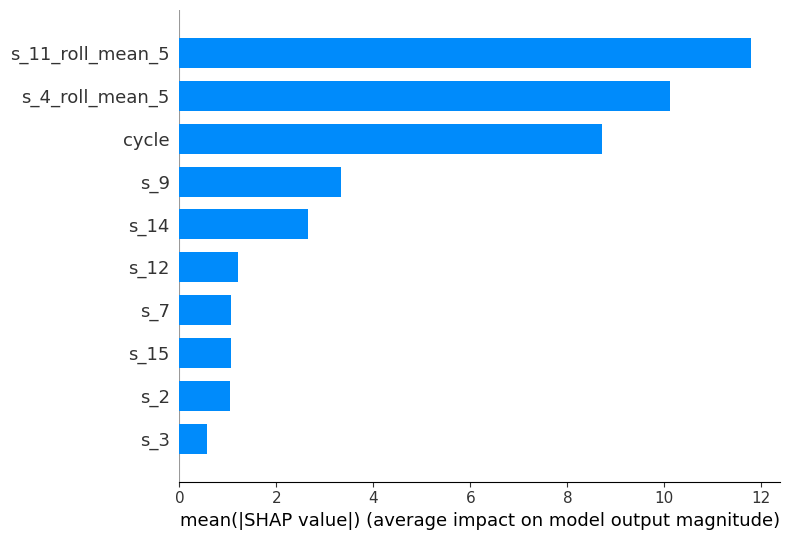

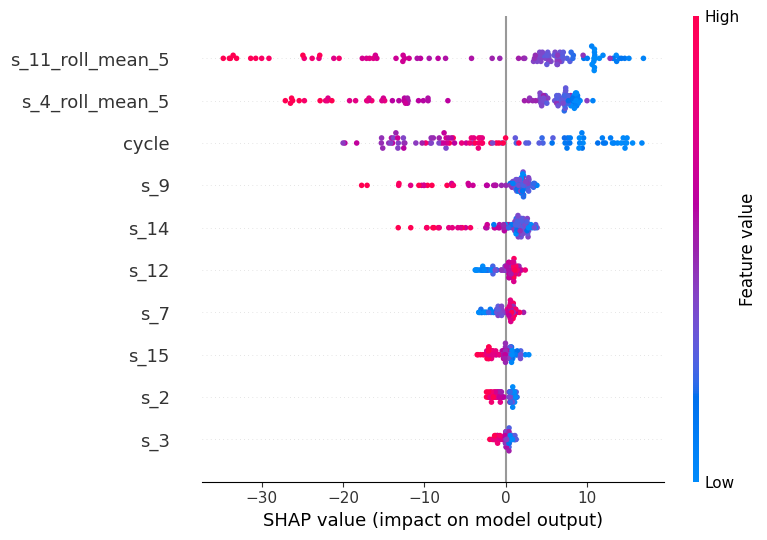

In [14]:
sample_size = min(100, len(X))
X_sample = X.sample(n=sample_size, random_state=42)
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_sample)

shap_importance = pd.DataFrame({
    "Feature": X_sample.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0),
}).sort_values("Mean_Absolute_SHAP", ascending=False).reset_index(drop=True)

display(shap_importance.head(10).round(4))
shap.summary_plot(shap_values, X_sample, plot_type="bar", max_display=10)
shap.summary_plot(shap_values, X_sample, max_display=10)

## 12. Results summary

Cross-validation rows and official-test rows are different evaluations; do not compare them directly.


In [15]:
cv_summary = cv_comparison[["Model", "Mean CV RMSE"]].rename(
    columns={"Mean CV RMSE": "RMSE"}
)
cv_summary.insert(0, "Evaluation", "All-cycle GroupKFold CV (training engines, uncapped target)")

test_summary = pd.DataFrame([
    {"Evaluation": "Official test (last cycle per engine)", "Model": "XGBoost, uncapped target", **uncapped_metrics},
    {"Evaluation": "Official test (last cycle per engine)", "Model": f"XGBoost, cap {RUL_CAP}", **final_metrics},
])

results_summary = pd.concat([cv_summary, test_summary], ignore_index=True)
display(results_summary.round(2))

,Evaluation,Model,RMSE,MAE,PHM08,Mean Error
0,"All-cycle GroupKFold CV (training engines, unc...",Linear Regression,40.05,NaN,NaN,NaN
1,"All-cycle GroupKFold CV (training engines, unc...",Random Forest,37.54,NaN,NaN,NaN
2,"All-cycle GroupKFold CV (training engines, unc...",XGBoost,37.24,NaN,NaN,NaN
3,Official test (last cycle per engine),"XGBoost, uncapped target",26.08,18.63,7587.51,11.72
4,Official test (last cycle per engine),"XGBoost, cap 120",17.92,13.20,549.26,-1.49


## 13. Conclusions and limitations

**Method**
- The target is remaining cycles to the last observed cycle of each training engine; the model is trained on a target capped at `RUL_CAP`.
- Rolling statistics are trailing and computed separately within each engine; GroupKFold keeps engines separated between training and validation folds.
- Official test metrics are final reporting results, not a tuning signal.

**Limitations**
- The capping idea and the 7–145 validation range were informed by official-test diagnostics, so the final test score may be optimistic relative to a fully untouched hold-out.
- Caps 110–125 are statistically close; cap 120 is a compromise, not a proven optimum.
- Capped models cannot predict RUL far above the cap, so engines with long remaining life are systematically under-predicted.
- PHM08 is an asymmetric exponential score; a few large errors dominate it, and it depends on the number of rows scored.
- Only FD001 (one operating condition, one fault mode) was used; no hyperparameter search was run beyond the fixed XGBoost settings.
- SHAP values describe how the fitted model uses features; they do not establish causation, and correlated features (for example `s_4` and `s_11` rolling means) share importance.
